# LLM Performance Analysis on Seen Data

This notebook generates performance metrics (Accuracy, Precision, Recall, F1) for LLM models on **human-labelled (seen) data** for the conspiracy classification task.

## Models Analyzed:
1. **Llama-3-8B-Instruct Zero-Shot** (`8b_zero`)
2. **Llama-3-8B-Instruct Few-Shot** (`8b_few`)
3. **Llama-3-8B-Instruct Few-Shot + Frames** (`8b_frame`)
4. **Llama-3.3-70B-Instruct Zero-Shot** (`70b_zero`)
5. **Llama-3.3-70B-Instruct Few-Shot** (`70b_few`)
6. **Llama-3.3-70B-Instruct Few-Shot + Frames** (`70b_frame`)

## Output:
- Performance comparison table with Accuracy, Precision, Recall, F1 metrics
- CSV export for paper inclusion
- LaTeX table format for paper inclusion


In [ ]:
# Setup & Imports
import pandas as pd
import numpy as np
from pathlib import Path
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
)
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Set plotting style
sns.set_theme(context="notebook", style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11

# Set paths
BASE = Path('/home/ashrafs/projects/Conspiracy-Proj')
DATA = BASE / 'Data'
OUT = BASE / 'outputs'
PUB_TABLES = BASE / 'publication' / 'tables'
PUB_FIGURES = BASE / 'publication' / 'figures'
PUB_TABLES.mkdir(exist_ok=True, parents=True)
PUB_FIGURES.mkdir(exist_ok=True, parents=True)

print("✓ Setup complete!")
print(f"Data directory: {DATA}")
print(f"Output directory: {OUT}")
print(f"Tables directory: {PUB_TABLES}")
print(f"Figures directory: {PUB_FIGURES}")


✓ Setup complete!
Data directory: /home/ashrafs/projects/Conspiracy-Proj/Data
Output directory: /home/ashrafs/projects/Conspiracy-Proj/outputs
Tables directory: /home/ashrafs/projects/Conspiracy-Proj/publication/tables


## 1. Load Human Annotations (Ground Truth)


In [8]:
# Load Human Annotations (Ground Truth)
print("Loading human annotations...")

# Human classifications
human_class_path = DATA / 'all_classifications.csv'
if not human_class_path.exists():
    raise FileNotFoundError(f"Human classification file not found: {human_class_path}")

human_class = pd.read_csv(human_class_path)
print(f"Loaded human classifications: {len(human_class):,} rows")

# Normalize booleans
BOOL_MAP = {'true': True, 'false': False, 'yes': True, 'no': False, 'y': True, 'n': False, '1': True, '0': False}
def parse_bool(s: pd.Series) -> pd.Series:
    v = s.astype(str).str.strip().str.lower().map(BOOL_MAP)
    unmapped = v.isna()
    if unmapped.any():
        num = pd.to_numeric(s[unmapped], errors='coerce')
        v.loc[unmapped & num.notna()] = (num[num.notna()] > 0).astype(bool)
    return v

# Create majority-vote aggregation
hc = human_class.copy()
hc['conspiracy_mv'] = parse_bool(hc['conspiracy'])

grp = hc.groupby('text_id', as_index=False)
agg = grp.agg(
    conspiracy_mv=('conspiracy_mv', lambda x: bool(np.mean(x.dropna()) >= 0.5) if len(x.dropna()) else np.nan),
)

print(f"\n✓ Human majority-vote rows: {len(agg):,}")
# Handle NaN values in conspiracy_mv
agg['conspiracy_mv'] = agg['conspiracy_mv'].fillna(False).astype(bool)
conspiratorial_count = agg['conspiracy_mv'].sum()
non_conspiratorial_count = len(agg) - conspiratorial_count
print(f"  - Conspiratorial: {conspiratorial_count:,} ({conspiratorial_count/len(agg):.1%})")
print(f"  - Non-conspiratorial: {non_conspiratorial_count:,} ({non_conspiratorial_count/len(agg):.1%})")


Loading human annotations...
Loaded human classifications: 3,243 rows

✓ Human majority-vote rows: 2,077
  - Conspiratorial: 543 (26.1%)
  - Non-conspiratorial: 1,534 (73.9%)


## 2. Load All Model Outputs


In [9]:
# Load All Model Outputs
print("Loading model outputs...\n")

# Model classification outputs (human-schema CSVs)
model_files = {
    '8b_zero': OUT / 'llama8b-zeroshot_all_classifications.csv',
    '8b_few': OUT / 'llama8b-fewshot_all_classifications.csv',
    '8b_frame': OUT / 'llama8b-frame_all_classifications.csv',
    '70b_zero': OUT / 'llama-3.3-70B-zeroshot_all_classifications.csv',
    '70b_few': OUT / 'llama-3.3-70B-fewshot_all_classifications.csv',
    '70b_frame': OUT / 'llama-3.3-70B-frame_all_classifications.csv',
}

# Model display names for paper
model_display_names = {
    '8b_zero': '8B Zero-Shot',
    '8b_few': '8B Few-Shot',
    '8b_frame': '8B Few-Shot+Frames',
    '70b_zero': '70B Zero-Shot',
    '70b_few': '70B Few-Shot',
    '70b_frame': '70B Few-Shot+Frames',
}

experiments = {}
missing_models = []

for name, path in model_files.items():
    if not path.exists():
        missing_models.append((name, model_display_names.get(name, name)))
        print(f"⚠ Missing: {name:12s} ({model_display_names.get(name, name)}) - {path.name}")
        continue
    
    df = pd.read_csv(path)
    
    # Parse booleans
    def parse_bool_local(s: pd.Series) -> pd.Series:
        v = s.astype(str).str.strip().str.lower().map(BOOL_MAP)
        unmapped = v.isna()
        if unmapped.any():
            num = pd.to_numeric(s[unmapped], errors='coerce')
            v.loc[unmapped & num.notna()] = (num[num.notna()] > 0).astype(bool)
        return v
    
    # Map conspiracy column
    if 'conspiracy' in df.columns:
        df['conspiracy'] = parse_bool_local(df['conspiracy'])
        df['is_conspiratorial'] = df['conspiracy']
    elif 'is_conspiratorial' in df.columns:
        df['is_conspiratorial'] = parse_bool_local(df['is_conspiratorial'])
    
    experiments[name] = df
    print(f"✓ {name:12s} ({model_display_names.get(name, name):25s}): {len(df):,} rows")

print(f"\n{'='*80}")
print(f"MODEL STATUS SUMMARY")
print(f"{'='*80}")
print(f"✓ Available models: {len(experiments)}/{len(model_files)}")
if missing_models:
    print(f"\n⚠ Missing/Still Running: {len(missing_models)}/{len(model_files)}")
    for name, disp_name in missing_models:
        print(f"   - {disp_name} ({name})")
print(f"{'='*80}")


Loading model outputs...

✓ 8b_zero      (8B Zero-Shot             ): 2,077 rows
✓ 8b_few       (8B Few-Shot              ): 2,077 rows
✓ 8b_frame     (8B Few-Shot+Frames       ): 2,077 rows
✓ 70b_zero     (70B Zero-Shot            ): 2,077 rows
✓ 70b_few      (70B Few-Shot             ): 2,077 rows
✓ 70b_frame    (70B Few-Shot+Frames      ): 2,077 rows

MODEL STATUS SUMMARY
✓ Available models: 6/6


## 3. Calculate Performance Metrics


In [10]:
# Build evaluation dataframe with consistent text_ids
def build_eval_df(exp_name, df, task='is_conspiratorial'):
    """Build evaluation dataframe for a single experiment and task."""
    key = 'text_id'
    if key not in df.columns or key not in agg.columns:
        return None
    
    # Get prediction column
    pred_col = task
    if pred_col not in df.columns:
        return None
    
    # Get ground truth column (only conspiracy)
    if task == 'is_conspiratorial':
        gt_col = 'conspiracy_mv'
    else:
        return None
    
    if gt_col not in agg.columns:
        return None
    
    # Merge
    merged = df[[key, pred_col]].merge(
        agg[[key, gt_col]], on=key, how='inner'
    )
    
    # Fill NaN human labels as False (conservative)
    merged[gt_col] = merged[gt_col].fillna(False)
    
    # Coerce to boolean
    merged[pred_col] = merged[pred_col].map({True: True, False: False}).astype(bool)
    merged[gt_col] = merged[gt_col].map({True: True, False: False}).astype(bool)
    
    return merged

# Compute metrics for all experiments (conspiracy only)
results = []
for exp_name, df in experiments.items():
    eval_df = build_eval_df(exp_name, df, 'is_conspiratorial')
    if eval_df is None:
        print(f"⚠ Could not build eval df for {exp_name}")
        continue
    
    pred_col = 'is_conspiratorial'
    gt_col = 'conspiracy_mv'
    
    y_true = eval_df[gt_col].to_numpy()
    y_pred = eval_df[pred_col].to_numpy()
    
    if len(y_true) == 0:
        print(f"⚠ No valid predictions for {exp_name}")
        continue
    
    # Compute metrics
    acc = accuracy_score(y_true, y_pred)
    p, r, f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average='binary', zero_division=0
    )
    
    results.append({
        'Model': model_display_names.get(exp_name, exp_name),
        'Model_Code': exp_name,
        'Accuracy': acc,
        'Precision': p,
        'Recall': r,
        'F1': f1,
        'N': len(y_true)
    })

metrics_df = pd.DataFrame(results)

print("✓ Performance metrics calculated for all available models")
print(f"\nTotal models evaluated: {len(metrics_df)}")


✓ Performance metrics calculated for all available models

Total models evaluated: 6


## 4. Display Performance Table


In [11]:
# Sort by F1 score (descending)
metrics_df_sorted = metrics_df.sort_values('F1', ascending=False).copy()

# Format for display
display_df = metrics_df_sorted.copy()
for col in ['Accuracy', 'Precision', 'Recall', 'F1']:
    display_df[col] = display_df[col].apply(lambda x: f"{x:.4f}")

print("=" * 80)
print("LLM PERFORMANCE METRICS ON SEEN DATA (Human-Labelled)")
print("=" * 80)
print(f"\nTask: Conspiracy Classification (Binary: Yes/No)")
print(f"Evaluation Metric: Accuracy, Precision, Recall, F1")
print(f"\n{'='*80}\n")

display(display_df[['Model', 'Accuracy', 'Precision', 'Recall', 'F1', 'N']])

print("\n" + "=" * 80)
if missing_models:
    print(f"\n⚠ Note: {len(missing_models)} model(s) not yet available:")
    for name, disp_name in missing_models:
        print(f"   - {disp_name}")
    print(f"\n   Re-run this notebook once experiments complete to see full results.")
print("=" * 80)


LLM PERFORMANCE METRICS ON SEEN DATA (Human-Labelled)

Task: Conspiracy Classification (Binary: Yes/No)
Evaluation Metric: Accuracy, Precision, Recall, F1




,Model,Accuracy,Precision,Recall,F1,N
3,70B Zero-Shot,0.7882,0.5798,0.6888,0.6296,2077
5,70B Few-Shot+Frames,0.7554,0.5223,0.7532,0.6169,2077
4,70B Few-Shot,0.7463,0.5097,0.7772,0.6156,2077
1,8B Few-Shot,0.7289,0.4884,0.7735,0.5987,2077
2,8B Few-Shot+Frames,0.7232,0.4818,0.7790,0.5954,2077
0,8B Zero-Shot,0.7882,0.6036,0.5525,0.5769,2077


## 5. Create Visualizations


✓ Saved visualization: /home/ashrafs/projects/Conspiracy-Proj/publication/figures/llm_performance_seen_data_comparison.png


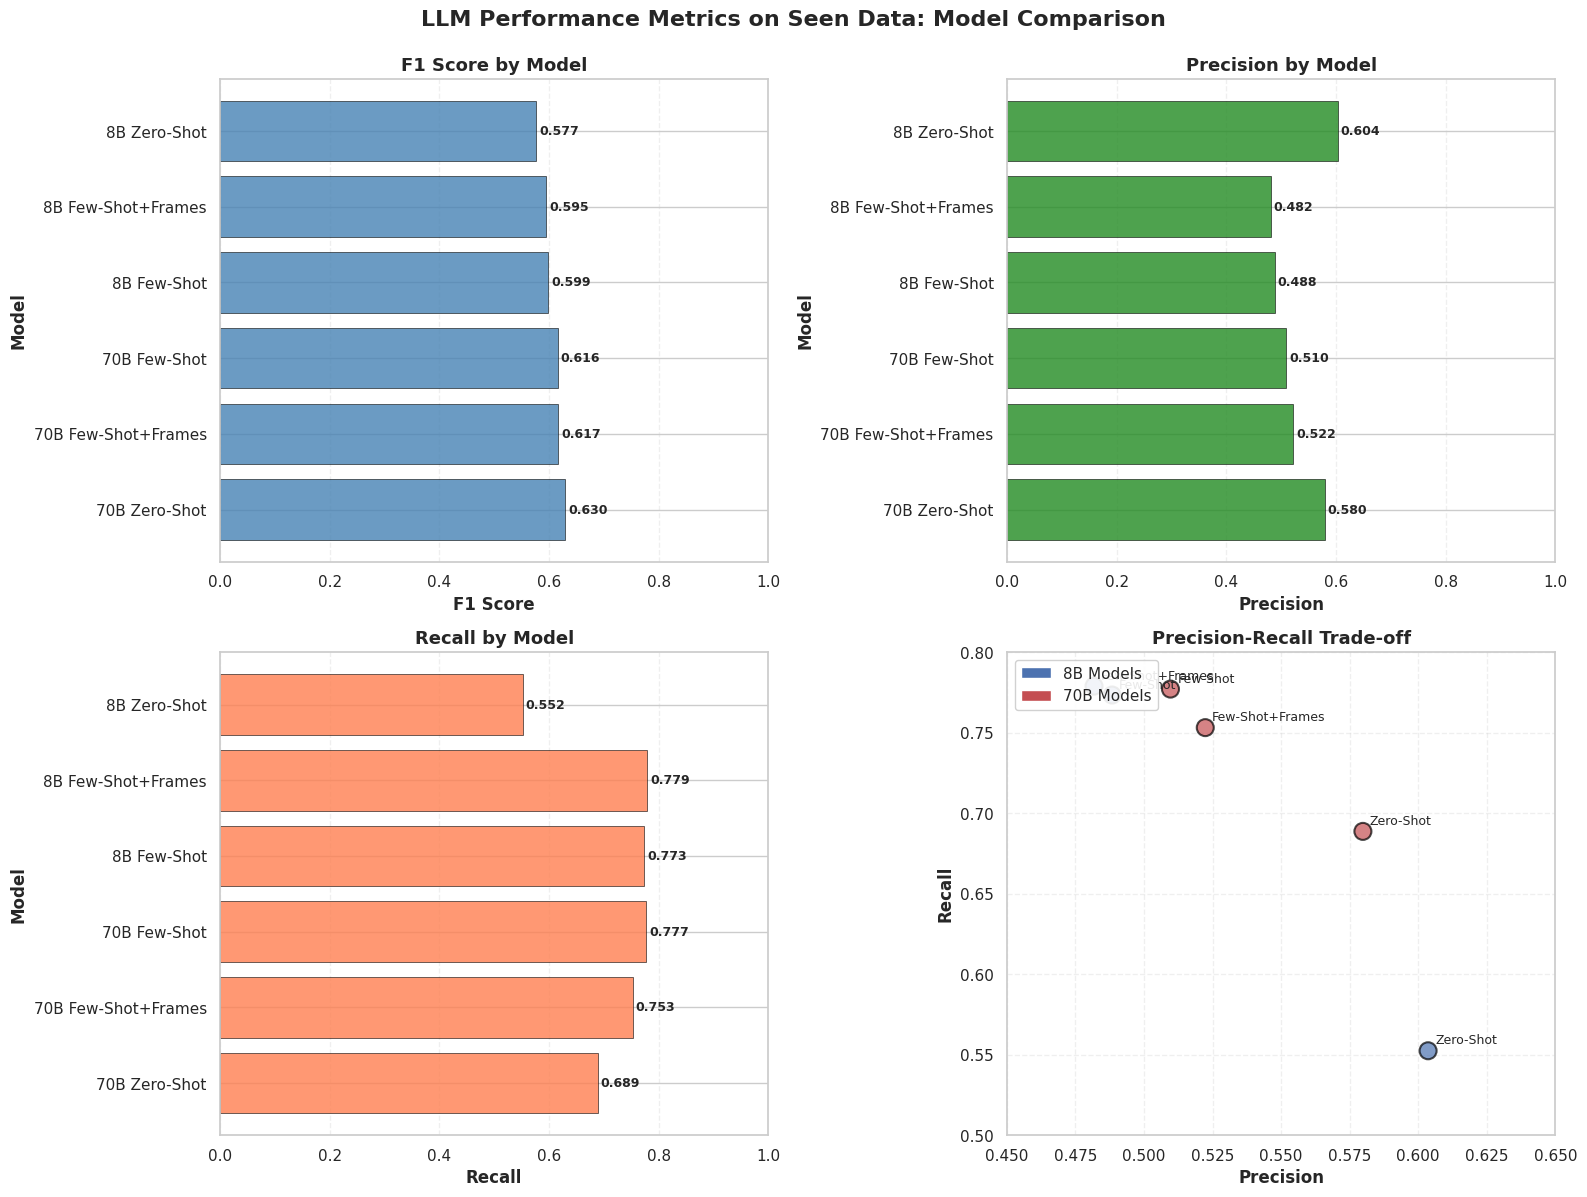

In [ ]:
# Create visualizations for LLM performance comparison
if len(metrics_df_sorted) > 0:
    # Create figure with subplots
    fig, axes = plt.subplots(2, 2, figsize=(16, 12))
    fig.suptitle('LLM Performance Metrics on Seen Data: Model Comparison', fontsize=16, fontweight='bold', y=0.995)
    
    # 1. F1 Score Comparison (Main metric)
    ax1 = axes[0, 0]
    bars1 = ax1.barh(metrics_df_sorted['Model'], metrics_df_sorted['F1'], 
                     color='steelblue', alpha=0.8, edgecolor='black', linewidth=0.5)
    ax1.set_xlabel('F1 Score', fontweight='bold', fontsize=12)
    ax1.set_ylabel('Model', fontweight='bold', fontsize=12)
    ax1.set_title('F1 Score by Model', fontweight='bold', fontsize=13)
    ax1.set_xlim(0, 1.0)
    ax1.grid(axis='x', alpha=0.3, linestyle='--')
    # Add value labels
    for i, bar in enumerate(bars1):
        width = bar.get_width()
        ax1.text(width + 0.005, bar.get_y() + bar.get_height()/2, 
                f'{width:.3f}', va='center', fontsize=9, fontweight='bold')
    
    # 2. Precision Comparison
    ax2 = axes[0, 1]
    bars2 = ax2.barh(metrics_df_sorted['Model'], metrics_df_sorted['Precision'], 
                     color='forestgreen', alpha=0.8, edgecolor='black', linewidth=0.5)
    ax2.set_xlabel('Precision', fontweight='bold', fontsize=12)
    ax2.set_ylabel('Model', fontweight='bold', fontsize=12)
    ax2.set_title('Precision by Model', fontweight='bold', fontsize=13)
    ax2.set_xlim(0, 1.0)
    ax2.grid(axis='x', alpha=0.3, linestyle='--')
    for i, bar in enumerate(bars2):
        width = bar.get_width()
        ax2.text(width + 0.005, bar.get_y() + bar.get_height()/2, 
                f'{width:.3f}', va='center', fontsize=9, fontweight='bold')
    
    # 3. Recall Comparison
    ax3 = axes[1, 0]
    bars3 = ax3.barh(metrics_df_sorted['Model'], metrics_df_sorted['Recall'], 
                     color='coral', alpha=0.8, edgecolor='black', linewidth=0.5)
    ax3.set_xlabel('Recall', fontweight='bold', fontsize=12)
    ax3.set_ylabel('Model', fontweight='bold', fontsize=12)
    ax3.set_title('Recall by Model', fontweight='bold', fontsize=13)
    ax3.set_xlim(0, 1.0)
    ax3.grid(axis='x', alpha=0.3, linestyle='--')
    for i, bar in enumerate(bars3):
        width = bar.get_width()
        ax3.text(width + 0.005, bar.get_y() + bar.get_height()/2, 
                f'{width:.3f}', va='center', fontsize=9, fontweight='bold')
    
    # 4. Precision-Recall Scatter Plot
    ax4 = axes[1, 1]
    # Color by model size (8B vs 70B)
    colors_map = ['#4C72B0' if '8B' in model else '#C44E52' for model in metrics_df_sorted['Model']]
    scatter = ax4.scatter(metrics_df_sorted['Precision'], metrics_df_sorted['Recall'], 
                         s=150, c=colors_map, alpha=0.7, edgecolors='black', linewidth=1.5)
    # Add model labels
    for idx, row in metrics_df_sorted.iterrows():
        ax4.annotate(row['Model'].replace('70B ', '').replace('8B ', ''), 
                    (row['Precision'], row['Recall']),
                    xytext=(5, 5), textcoords='offset points', fontsize=9)
    ax4.set_xlabel('Precision', fontweight='bold', fontsize=12)
    ax4.set_ylabel('Recall', fontweight='bold', fontsize=12)
    ax4.set_title('Precision-Recall Trade-off', fontweight='bold', fontsize=13)
    ax4.set_xlim(0.45, 0.65)
    ax4.set_ylim(0.50, 0.80)
    ax4.grid(alpha=0.3, linestyle='--')
    # Add legend for model sizes
    from matplotlib.patches import Patch
    legend_elements = [Patch(facecolor='#4C72B0', label='8B Models'),
                      Patch(facecolor='#C44E52', label='70B Models')]
    ax4.legend(handles=legend_elements, loc='upper left', framealpha=0.9)
    
    plt.tight_layout()
    
    # Save figure
    fig_path = PUB_FIGURES / 'llm_performance_seen_data_comparison.png'
    plt.savefig(fig_path, dpi=300, bbox_inches='tight', facecolor='white')
    print(f"✓ Saved visualization: {fig_path}")
    
    plt.show()


### Single F1 Comparison Plot (Paper-ready)


✓ Saved single F1 comparison plot: /home/ashrafs/projects/Conspiracy-Proj/publication/figures/llm_performance_seen_data_f1_comparison.png


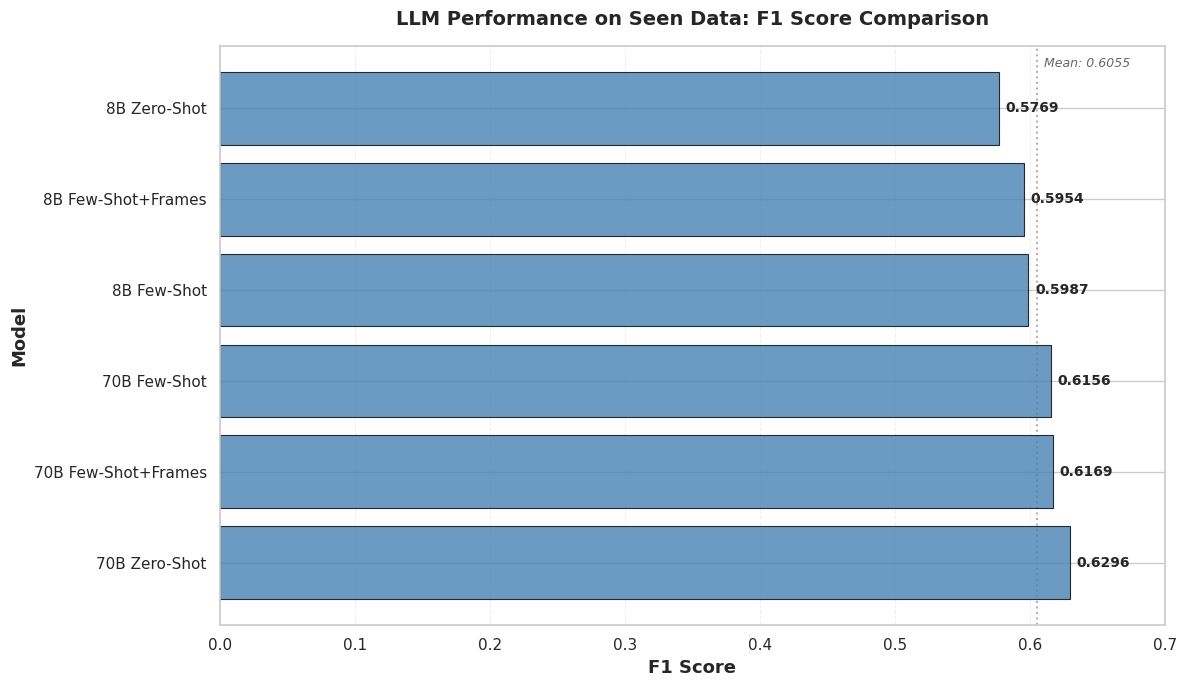

In [14]:
# Create a cleaner single F1 comparison plot (better for paper)
fig2, ax = plt.subplots(1, 1, figsize=(12, 7))

# Sort by F1 for display
bars = ax.barh(metrics_df_sorted['Model'], metrics_df_sorted['F1'], 
               color='steelblue', alpha=0.8, edgecolor='black', linewidth=0.8)

ax.set_xlabel('F1 Score', fontweight='bold', fontsize=13)
ax.set_ylabel('Model', fontweight='bold', fontsize=13)
ax.set_title('LLM Performance on Seen Data: F1 Score Comparison', fontweight='bold', fontsize=14, pad=15)
ax.set_xlim(0, 0.70)
ax.grid(axis='x', alpha=0.3, linestyle='--', linewidth=0.8)

# Add value labels on bars
for i, bar in enumerate(bars):
    width = bar.get_width()
    ax.text(width + 0.005, bar.get_y() + bar.get_height()/2, 
            f'{width:.4f}', va='center', fontsize=10, fontweight='bold')

# Add vertical reference line at mean F1
mean_f1 = metrics_df_sorted['F1'].mean()
ax.axvline(x=mean_f1, color='gray', linestyle=':', linewidth=1.5, alpha=0.6, zorder=0)
ax.text(mean_f1 + 0.005, len(metrics_df_sorted) - 0.5, f'Mean: {mean_f1:.4f}', 
        fontsize=9, style='italic', alpha=0.7, va='center')

plt.tight_layout()

# Save figure
fig_path_single = PUB_FIGURES / 'llm_performance_seen_data_f1_comparison.png'
plt.savefig(fig_path_single, dpi=300, bbox_inches='tight', facecolor='white')
print(f"✓ Saved single F1 comparison plot: {fig_path_single}")

plt.show()


### Model Size and Prompt Strategy Comparison


✓ Saved model size and strategy comparison: /home/ashrafs/projects/Conspiracy-Proj/publication/figures/llm_performance_seen_data_size_strategy.png


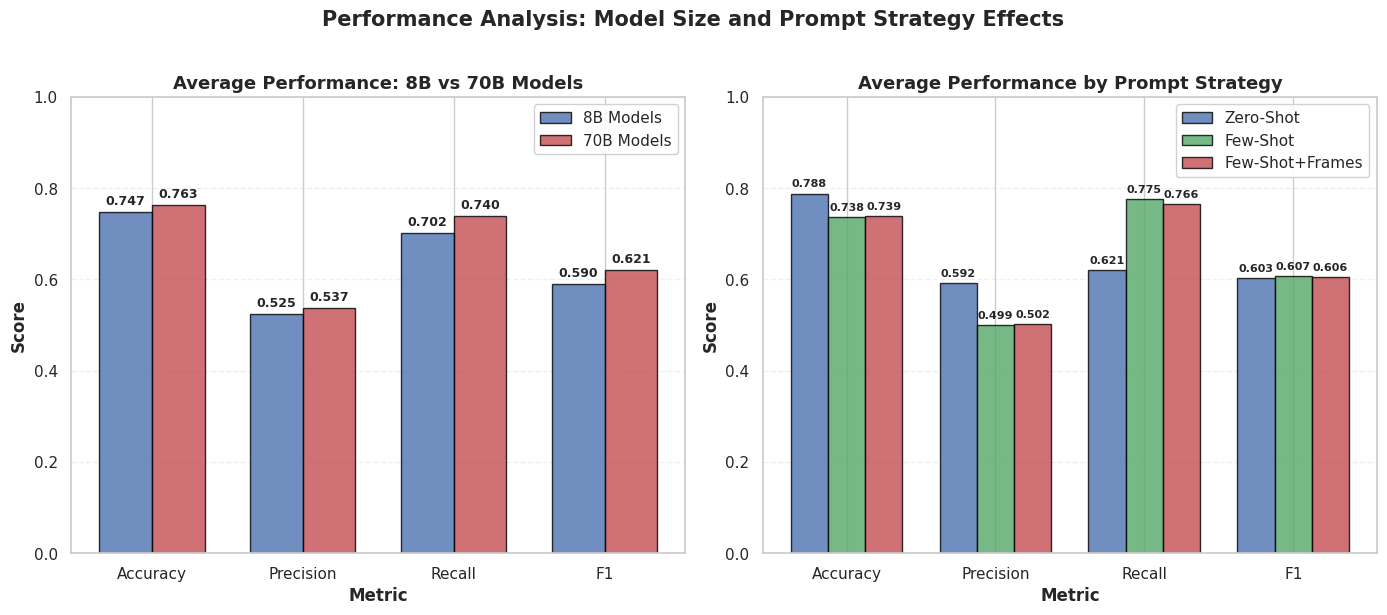

In [ ]:
# Create comparison plots for model size and prompt strategy
fig3, axes = plt.subplots(1, 2, figsize=(14, 6))
fig3.suptitle('Performance Analysis: Model Size and Prompt Strategy Effects', fontsize=15, fontweight='bold', y=1.02)

# 1. Model Size Comparison (8B vs 70B)
ax1 = axes[0]
df_8b = metrics_df_sorted[metrics_df_sorted['Model_Code'].str.startswith('8b')]
df_70b = metrics_df_sorted[metrics_df_sorted['Model_Code'].str.startswith('70b')]

if len(df_8b) > 0 and len(df_70b) > 0:
    categories = ['Accuracy', 'Precision', 'Recall', 'F1']
    x = np.arange(len(categories))
    width = 0.35
    
    avg_8b = [df_8b[cat].mean() for cat in categories]
    avg_70b = [df_70b[cat].mean() for cat in categories]
    
    bars1 = ax1.bar(x - width/2, avg_8b, width, label='8B Models', color='#4C72B0', alpha=0.8, edgecolor='black')
    bars2 = ax1.bar(x + width/2, avg_70b, width, label='70B Models', color='#C44E52', alpha=0.8, edgecolor='black')
    
    # Add value labels
    for bars in [bars1, bars2]:
        for bar in bars:
            height = bar.get_height()
            ax1.text(bar.get_x() + bar.get_width()/2., height + 0.01,
                    f'{height:.3f}', ha='center', va='bottom', fontsize=9, fontweight='bold')
    
    ax1.set_xlabel('Metric', fontweight='bold', fontsize=12)
    ax1.set_ylabel('Score', fontweight='bold', fontsize=12)
    ax1.set_title('Average Performance: 8B vs 70B Models', fontweight='bold', fontsize=13)
    ax1.set_xticks(x)
    ax1.set_xticklabels(categories)
    ax1.set_ylim(0, 1.0)
    ax1.legend(loc='upper right', framealpha=0.9)
    ax1.grid(axis='y', alpha=0.3, linestyle='--')

# 2. Prompt Strategy Comparison (Zero-Shot vs Few-Shot vs Few-Shot+Frames)
ax2 = axes[1]
df_zero = metrics_df_sorted[metrics_df_sorted['Model_Code'].str.endswith('_zero')]
df_few = metrics_df_sorted[metrics_df_sorted['Model_Code'].str.endswith('_few')]
df_frame = metrics_df_sorted[metrics_df_sorted['Model_Code'].str.endswith('_frame')]

if len(df_zero) > 0 and len(df_few) > 0:
    categories = ['Accuracy', 'Precision', 'Recall', 'F1']
    x = np.arange(len(categories))
    width = 0.25
    
    avg_zero = [df_zero[cat].mean() if len(df_zero) > 0 else 0 for cat in categories]
    avg_few = [df_few[cat].mean() if len(df_few) > 0 else 0 for cat in categories]
    avg_frame = [df_frame[cat].mean() if len(df_frame) > 0 else 0 for cat in categories]
    
    bars1 = ax2.bar(x - width, avg_zero, width, label='Zero-Shot', color='#4C72B0', alpha=0.8, edgecolor='black')
    bars2 = ax2.bar(x, avg_few, width, label='Few-Shot', color='#55A868', alpha=0.8, edgecolor='black')
    bars3 = ax2.bar(x + width, avg_frame, width, label='Frame-Guided', color='#C44E52', alpha=0.8, edgecolor='black')
    
    # Add value labels
    for bars in [bars1, bars2, bars3]:
        for bar in bars:
            height = bar.get_height()
            if height > 0:
                ax2.text(bar.get_x() + bar.get_width()/2., height + 0.01,
                        f'{height:.3f}', ha='center', va='bottom', fontsize=8, fontweight='bold')
    
    ax2.set_xlabel('Metric', fontweight='bold', fontsize=12)
    ax2.set_ylabel('Score', fontweight='bold', fontsize=12)
    ax2.set_title('Average Performance by Prompt Strategy', fontweight='bold', fontsize=13)
    ax2.set_xticks(x)
    ax2.set_xticklabels(categories)
    ax2.set_ylim(0, 1.0)
    ax2.legend(loc='upper right', framealpha=0.9)
    ax2.grid(axis='y', alpha=0.3, linestyle='--')

plt.tight_layout()

# Save figure
fig_path_comparison = PUB_FIGURES / 'llm_performance_seen_data_size_strategy.png'
plt.savefig(fig_path_comparison, dpi=300, bbox_inches='tight', facecolor='white')
print(f"✓ Saved model size and strategy comparison: {fig_path_comparison}")

plt.show()


## 6. Export Results


In [16]:
# Export as CSV
csv_path = PUB_TABLES / 'llm_performance_seen_data.csv'
metrics_df_sorted[['Model', 'Accuracy', 'Precision', 'Recall', 'F1', 'N']].to_csv(
    csv_path, index=False, float_format='%.4f'
)
print(f"✓ Exported CSV: {csv_path}")

# Export as LaTeX table (canonical version - includes N column and table environment)
latex_path = PUB_TABLES / 'llm_performance_seen_data.tex'

# Create LaTeX table with proper formatting (include N column)
latex_table = metrics_df_sorted[['Model', 'Accuracy', 'Precision', 'Recall', 'F1', 'N']].copy()
for col in ['Accuracy', 'Precision', 'Recall', 'F1']:
    latex_table[col] = latex_table[col].apply(lambda x: f"{x:.4f}")

latex_str = "\\begin{table*}[t]\n"
latex_str += "\\centering\n"
latex_str += "\\caption{LLM Performance Metrics on Seen Data (Human-Labelled)}\n"
latex_str += "\\label{tab:llm_performance_seen}\n"
latex_str += "\\begin{tabular}{lccccc}\n"
latex_str += "\\toprule\n"
latex_str += "Model & Accuracy & Precision & Recall & F1 & N \\\\\n"
latex_str += "\\midrule\n"

for _, row in latex_table.iterrows():
    # Escape underscores in model names for LaTeX
    model_name = row['Model'].replace('_', '\\_')
    latex_str += f"{model_name} & {row['Accuracy']} & {row['Precision']} & {row['Recall']} & {row['F1']} & {int(row['N'])} \\\\\n"

latex_str += "\\bottomrule\n"
latex_str += "\\end{tabular}\n"
latex_str += "\\end{table*}\n"

with open(latex_path, 'w') as f:
    f.write(latex_str)

print(f"✓ Exported LaTeX table: {latex_path}")

print("\n" + "=" * 80)
print("Export Summary:")
print(f"  - CSV: {csv_path}")
print(f"  - LaTeX: {latex_path}")
print("=" * 80)


✓ Exported CSV: /home/ashrafs/projects/Conspiracy-Proj/publication/tables/llm_performance_seen_data.csv
✓ Exported LaTeX table: /home/ashrafs/projects/Conspiracy-Proj/publication/tables/llm_performance_seen_data.tex

Export Summary:
  - CSV: /home/ashrafs/projects/Conspiracy-Proj/publication/tables/llm_performance_seen_data.csv
  - LaTeX: /home/ashrafs/projects/Conspiracy-Proj/publication/tables/llm_performance_seen_data.tex


In [17]:
# Summary statistics
print("=" * 80)
print("SUMMARY STATISTICS")
print("=" * 80)

if len(metrics_df_sorted) > 0:
    print(f"\nBest F1 Score: {metrics_df_sorted.iloc[0]['Model']} (F1={metrics_df_sorted.iloc[0]['F1']:.4f})")
    print(f"Best Precision: {metrics_df_sorted.loc[metrics_df_sorted['Precision'].idxmax(), 'Model']} (Precision={metrics_df_sorted['Precision'].max():.4f})")
    print(f"Best Recall: {metrics_df_sorted.loc[metrics_df_sorted['Recall'].idxmax(), 'Model']} (Recall={metrics_df_sorted['Recall'].max():.4f})")
    print(f"Best Accuracy: {metrics_df_sorted.loc[metrics_df_sorted['Accuracy'].idxmax(), 'Model']} (Accuracy={metrics_df_sorted['Accuracy'].max():.4f})")
    
    print(f"\nAverage Metrics Across All Models:")
    print(f"  - Accuracy: {metrics_df_sorted['Accuracy'].mean():.4f} (±{metrics_df_sorted['Accuracy'].std():.4f})")
    print(f"  - Precision: {metrics_df_sorted['Precision'].mean():.4f} (±{metrics_df_sorted['Precision'].std():.4f})")
    print(f"  - Recall: {metrics_df_sorted['Recall'].mean():.4f} (±{metrics_df_sorted['Recall'].std():.4f})")
    print(f"  - F1: {metrics_df_sorted['F1'].mean():.4f} (±{metrics_df_sorted['F1'].std():.4f})")
    
    # Compare 8B vs 70B
    df_8b = metrics_df_sorted[metrics_df_sorted['Model_Code'].str.startswith('8b')]
    df_70b = metrics_df_sorted[metrics_df_sorted['Model_Code'].str.startswith('70b')]
    
    if len(df_8b) > 0 and len(df_70b) > 0:
        print(f"\n8B Models Average F1: {df_8b['F1'].mean():.4f}")
        print(f"70B Models Average F1: {df_70b['F1'].mean():.4f}")
        print(f"Improvement (70B vs 8B): {((df_70b['F1'].mean() - df_8b['F1'].mean()) / df_8b['F1'].mean() * 100):.2f}%")
        
        # Compare prompt types
        df_zero = metrics_df_sorted[metrics_df_sorted['Model_Code'].str.endswith('_zero')]
        df_few = metrics_df_sorted[metrics_df_sorted['Model_Code'].str.endswith('_few')]
        df_frame = metrics_df_sorted[metrics_df_sorted['Model_Code'].str.endswith('_frame')]
        
        if len(df_zero) > 0:
            print(f"\nZero-Shot Average F1: {df_zero['F1'].mean():.4f}")
        if len(df_few) > 0:
            print(f"Few-Shot Average F1: {df_few['F1'].mean():.4f}")
        if len(df_frame) > 0:
            print(f"Few-Shot+Frames Average F1: {df_frame['F1'].mean():.4f}")
        
        if len(df_few) > 0 and len(df_zero) > 0:
            print(f"Few-Shot vs Zero-Shot improvement: {((df_few['F1'].mean() - df_zero['F1'].mean()) / df_zero['F1'].mean() * 100):.2f}%")
        if len(df_frame) > 0 and len(df_few) > 0:
            print(f"Few-Shot+Frames vs Few-Shot improvement: {((df_frame['F1'].mean() - df_few['F1'].mean()) / df_few['F1'].mean() * 100):.2f}%")

print("=" * 80)


SUMMARY STATISTICS

Best F1 Score: 70B Zero-Shot (F1=0.6296)
Best Precision: 8B Zero-Shot (Precision=0.6036)
Best Recall: 8B Few-Shot+Frames (Recall=0.7790)
Best Accuracy: 70B Zero-Shot (Accuracy=0.7882)

Average Metrics Across All Models:
  - Accuracy: 0.7550 (±0.0282)
  - Precision: 0.5309 (±0.0499)
  - Recall: 0.7207 (±0.0892)
  - F1: 0.6055 (±0.0189)

8B Models Average F1: 0.5903
70B Models Average F1: 0.6207
Improvement (70B vs 8B): 5.15%

Zero-Shot Average F1: 0.6033
Few-Shot Average F1: 0.6072
Few-Shot+Frames Average F1: 0.6061
Few-Shot vs Zero-Shot improvement: 0.64%
Few-Shot+Frames vs Few-Shot improvement: -0.17%
